# Lab: Relationships in Space and Time

Select **two distinct datasets that each contain both spatial and temporal information**. Ask **one research question for each dataset** and answer it using the six-step reproducible analysis workflow. Create **two different types of Plotly Express figures for each question**, for a total of two research questions and four figures.

Together, each pair of figures must help answer where and when the pattern occurs. A map and a time-series plot are one useful combination; other combinations are welcome when you explain how they address both space and time.

## Learning goals

- Select and document datasets with usable location and time features.
- Ask focused questions that connect a measurement or event count to both space and time.
- Prepare dates, geographic identifiers, and summaries appropriately for the question.
- Create and compare two complementary interactive figures for each question.
- Check plotted values and ordering against the records.
- Support conclusions with evidence and explain the limitations of the data and displays.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each dataset. Inspect missing values during Data; use Check to investigate the actual figures and calculations. Use separate code cells for individual operations and add cells as needed.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code, reading the source documentation, and checking every claim against your output. Complete the AI-use reflection at the end.

## Select your two datasets

Each dataset needs:

- A documented publisher and feature definitions or data dictionary.
- A usable **time feature**, such as a timestamp, date, month, or year, with observations from multiple times.
- A usable **spatial feature**, such as coordinates, station locations, or named geographic areas with matching identifiers, covering multiple places or a moving object's locations.
- A quantitative measurement with known units, or event records that support a meaningful count.
- Enough usable observations to compare places and periods. A file with dates from one fixed location alone will not support a spatial comparison.

Use two distinct datasets, not two filters of the same file. Choose your own questions and records rather than reproducing a worked lecture example. The suggestions below are starting points, not required choices. You may select another documented source.

Choose manageable geographic and time ranges before downloading. A country or city name does not automatically provide coordinates; document any station lookup, geographic-code lookup, or boundary file you need. Save fixed copies in this notebook's `data` folder, preserve the original records, and use relative paths. Include supporting lookup files with your submission.

### Candidate datasets

| Candidate and source | Useful spatial and time information | Possible question and figure pair |
| --- | --- | --- |
| [USGS earthquake catalog](https://earthquake.usgs.gov/earthquakes/search/) and [CSV field definitions](https://earthquake.usgs.gov/earthquakes/feed/v1.0/csv.php) | Event time, coordinates, magnitude, and depth. Limit the dates, geographic bounds, and magnitude range; download CSV. | Where did recorded earthquakes cluster during a selected period, and how did monthly counts change? Use a point or density map and a monthly count plot. |
| [NOAA daily weather observations](https://www.ncei.noaa.gov/cdo-web/search) and [GHCNd documentation](https://www.ncei.noaa.gov/products/land-based-station/global-historical-climatology-network-daily) | Station identifiers, dates, temperature or precipitation, and documented station locations. Select several stations and the same time span. | How did monthly precipitation differ among selected locations during a year? Use a station map of monthly summaries and a line plot or location-by-month heatmap. |
| [EPA daily air-quality data](https://www.epa.gov/outdoor-air-quality-data/download-daily-data) and [file documentation](https://aqs.epa.gov/aqsweb/airdata/download_files.html) | Monitor or county identifiers, dates, pollutant measurements or AQI. Use one pollutant and compatible units; obtain station coordinates if making a point map. | Where and when were PM2.5 concentrations highest among selected monitors? Use a map and a time-series plot grouped by monitor. |
| [NOAA Storm Events Database](https://www.ncei.noaa.gov/access/storm-events-database/) | Event dates, states/counties, event types, and locations when reported. Start with one event type, a few states, and a limited period. | How did reported hail-event counts vary across selected counties and months? Use a county choropleth and a county-by-month heatmap. County boundaries/codes are needed for the map. |

Adapt the question to the fields actually available. Counts of reported events or monitor observations can reflect reporting and sampling effort as well as the underlying phenomenon. Do not treat missing observations as zero events or average measurements with incompatible units.

## Choose two complementary figures per question

Choose **different chart types**, not two copies that differ only in color, title, filter, or static-versus-animated display. You may reuse a useful chart type with the second dataset. An animation counts as one figure, regardless of its number of frames. Animation is optional; a well-chosen static comparison can be easier to interpret.

| Figure | Plotly Express tools | What it can help you see |
| --- | --- | --- |
| Time-series line plot | `px.line()` | How a measurement changes over time; color or separate panels can distinguish locations. Sort dates within each series before connecting points. |
| Point or bubble map | `px.scatter_geo()` or `px.scatter_map()` | Where observations occur; color and size can show quantitative values. Time can appear in hover information, filters, or animation. |
| Choropleth | `px.choropleth()` | How an area-level summary varies geographically, optionally animated by period. Match country/state codes or supply matching GeoJSON boundaries. |
| Bubble scatterplot | `px.scatter()` | How two quantitative features relate; geographic groups and time can be represented by color and animation. Explain how location is represented if this replaces a map. |
| Geographic path — an additional option | `px.line_geo()` or `px.line_map()` | A recorded route or moving object's sequence of positions. Sort within each tracked object; do not connect unrelated events into a path. |
| Spatial density map — an additional option | `px.density_map()` | Where many nearby point observations concentrate. The smoothing radius affects the appearance; this is not automatically a rate or a map of risk. |
| Location-by-time heatmap — an additional option | `px.imshow()` | Rows represent locations, columns represent ordered periods, and color represents a count or measurement. Summarize to one value per location-period first. |

Use the [Plotly map guide](https://plotly.com/python/map-configuration/), [heatmap guide](https://plotly.com/python/heatmaps/), and [animation guide](https://plotly.com/python/animations/) for examples and parameters. Tile maps need access to background tiles; geographic maps may also need internet access for boundary outlines.

### Starting patterns for additional chart types

These are **adaptation examples**, not code to run unchanged. Replace the DataFrame and feature names with yours. They do not add requirements to your four figures.

**Path of a tracked object:** only use this when consecutive rows describe the same object's movement.

```python
track_df.sort_values(['object_id', 'date'], inplace=True)
fig = px.line_geo(track_df, lat='latitude', lon='longitude',
                  color='object_id', hover_data=['date'],
                  title='Recorded paths')
fig.update_layout(height=500)
fig.show()
```

**Density of point observations:** omit `z` to give every row equal weight. Document any deliberate weighting.

```python
fig = px.density_map(events_df, lat='latitude', lon='longitude',
                     radius=15, map_style='open-street-map',
                     title='Concentration of recorded events')
fig.update_layout(height=500)
fig.show()
```

**Location-by-month heatmap:** this example uses a mean measurement. Use a sum or count only when that statistic answers your question. Missing cells remain missing unless you can establish that a zero is appropriate.

```python
observations_df['month'] = observations_df['date'].dt.to_period('M').astype(str)
monthly_df = observations_df.groupby(['location', 'month'])['value'].mean().reset_index()
grid = monthly_df.pivot(index='location', columns='month', values='value')
grid = grid.reindex(sorted(grid.columns), axis=1)
fig = px.imshow(grid, aspect='auto',
                labels={'x':'Month', 'y':'Location', 'color':'Mean value'},
                title='Mean measurement by location and month')
fig.update_layout(height=500)
fig.show()
```

### Make the comparison interpretable

Use descriptive titles, labels with units, and informative hover fields. Start with `fig.update_layout(height=500)` and adjust only if needed. Keep scales consistent when comparing frames or panels. Use a manageable number of time periods—monthly, quarterly, or yearly frames often work better than hundreds of daily frames. Explain any aggregation and retain the original dates.

For maps, confirm that geographic codes match the boundaries and that points appear in plausible places. Numeric identifiers are not quantitative measurements. A colored area or large marker does not necessarily mean greater risk: consider population, area, observation effort, and what the encoded value actually measures.

In [1]:
import pandas as pd
import plotly.express as px

## Investigation 1: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer: How did the monthly number of recorded earthquakes of magnitude 4.0 or higher differ between the northern and southern parts of my western U.S. study area in 2024? I split the area at 37°N, and I predict the South had more earthquakes overall. Looking at both location and time helps me see if the South had more throughout the year or if a few months made the difference. 

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer: I used the ANSS Comprehensive Earthquake Catalog published by the U.S. Geological Survey (USGS). I accessed it on November 15, 2026, and saved the results as data/earthquakes_2024.csv. The CSV includes latitude and longitude, so I used no separate lookup or boundary files. Direct source CSV · CSV field definitions

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer: Each row is one recorded earthquake of magnitude 4.0 or higher. The records cover January through December 2024 in UTC and include parts of the western U.S. and nearby offshore areas between 32°N and 42°N and 125°W and 114°W. Seismic networks detected the earthquakes and contributed the records to the USGS catalog.

In [2]:
quakes = pd.read_csv(
    "data/earthquakes_2024.csv",
    dtype={"id": "string"},
    parse_dates=["time"]
)

In [3]:
quakes.head()
quakes.tail
quakes.shape

(60, 22)

In [4]:
quakes.info()
quakes.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   time             60 non-null     datetime64[ns, UTC]
 1   latitude         60 non-null     float64            
 2   longitude        60 non-null     float64            
 3   depth            60 non-null     float64            
 4   mag              60 non-null     float64            
 5   magType          60 non-null     object             
 6   nst              60 non-null     int64              
 7   gap              60 non-null     int64              
 8   dmin             60 non-null     float64            
 9   rms              60 non-null     float64            
 10  net              60 non-null     object             
 11  id               60 non-null     string             
 12  updated          60 non-null     object             
 13  place            60 no

time                0
latitude            0
longitude           0
depth               0
mag                 0
magType             0
nst                 0
gap                 0
dmin                0
rms                 0
net                 0
id                  0
updated             0
place               0
type                0
horizontalError     5
depthError          0
magError           50
magNst              1
status              0
locationSource      0
magSource           0
dtype: int64

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
| `id | Unique USGS event ID | Categorical | String | 0 |
| `time` | Original earthquake timestamp in UTC | Temporal | UTC datetime | 0 |
| `event_time` | UTC timestamp used to group events by month | Temporal | UTC datetime | 0 |
| `latitude` | Latitude in decimal degrees | Quantitative | Float | 0 |
| `longitude` | Longitude in decimal degrees | Quantitative | Float | 0 |
| `mag` | Reported earthquake magnitude | Quantitative | Float | 0 |
| `depth` | Earthquake depth in kilometers | Quantitative | Float | 0 |
| `place` | USGS description of the earthquake location | Categorical | String | 0 |
| `month` | UTC month in `YYYY-MM` format | Temporal | String | 0 |
| `zone` | North at or above 37°N, South below 37°N | Categorical | String | 0 |
| `count` | Number of earthquakes per month and zone | Quantitative | Integer | 0 |

Use quantitative, categorical, or temporal for feature type.

Your answer:

**Which observations and features will you use? Explain your time periods, geographic grouping, filtering, missing-value decisions, and any counts, means, sums, or rates.**

Your answer: I used the recorded earthquakes of magnitude 4.0 or higher from the 2024 USGS query. I grouped them by UTC month and split the study area at 37°N. I used the timestamps for the months, latitude for the zones, and latitude and longitude for the map. The map also uses magnitude, depth, and place in its display. The fields I used had no missing values. I counted events for each month and zone and used zero when the query returned no matching events there.

In [5]:
events = quakes.assign(event_time=pd.to_datetime(quakes["time"], utc=True))
events["month"] = events["event_time"].dt.strftime("%Y-%m")
events["zone"] = events["latitude"].ge(37).map({True: "North", False: "South"})
events = events.sort_values(["zone", "event_time"])

months = pd.period_range("2024-01", "2024-12", freq="M").astype(str)
counts = (
    pd.crosstab(events["month"], events["zone"])
    .reindex(index=months, columns=["North", "South"], fill_value=0)
    .rename_axis(index="month", columns="zone")
    .reset_index()
    .melt(id_vars="month", var_name="zone", value_name="count")
)

print("Original records:", len(quakes))
print("Retained records:", len(events))
print("Geographic lookup: none needed")

Original records: 60
Retained records: 60
Geographic lookup: none needed


**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer: I removed zero records. All 60 records from the saved query had the fields I needed. Each row in the monthly summary represents one month and one zone, with the number of recorded earthquakes for that combination. Each row in the map data still represents one earthquake.

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer: I will use a line chart and a point map. The line chart puts the UTC month on the x-axis, the number of recorded earthquakes on the y-axis, and uses color for the North and South zones. It shows when each zone had more earthquakes. The map uses latitude and longitude to show where each earthquake occurred, marker size for magnitude, and color for zone. The hover details show the event time, place, and depth. Both charts use the same 60 records. 

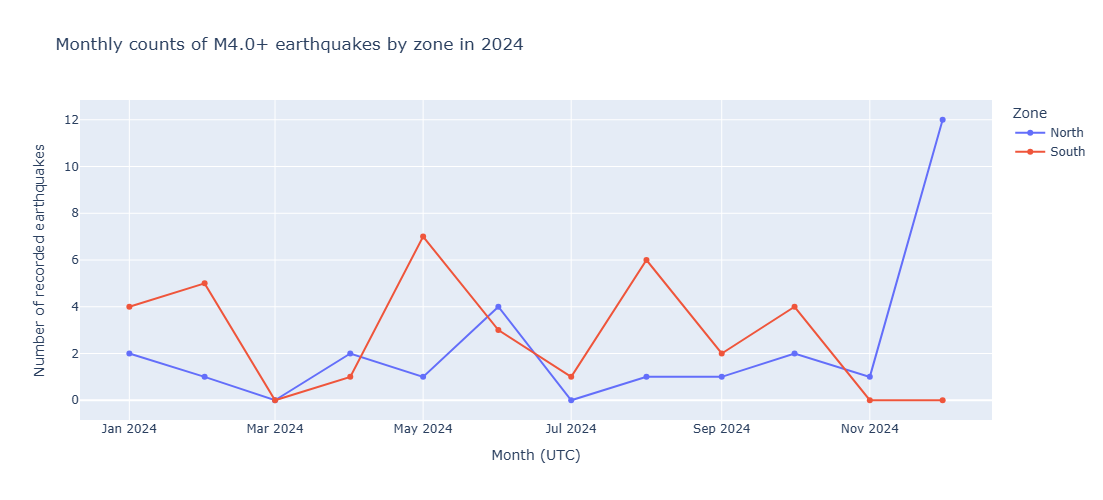

In [6]:
quake_line = px.line(
    counts,
    x="month",
    y="count",
    color="zone",
    markers=True,
    category_orders={"month": list(months)},
    labels={
        "month": "Month (UTC)",
        "count": "Number of recorded earthquakes",
        "zone": "Zone"
    },
    title="Monthly counts of M4.0+ earthquakes by zone in 2024"
)
quake_line.update_layout(height=500)
quake_line.show()

**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer:

In [7]:
quake_map = px.scatter_geo(
    events,
    lat="latitude",
    lon="longitude",
    color="zone",
    size="mag",
    hover_name="place",
    hover_data=["time", "depth"],
    category_orders={"zone": ["North", "South"]},
    labels={
        "zone": "Zone",
        "time": "Event time (UTC)",
        "depth": "Depth (km)",
        "mag": "Magnitude"
    },
    title="Locations of recorded M4.0+ earthquakes in 2024"
)
quake_map.update_geos(fitbounds="locations", showland=True, showsubunits=True)
quake_map.update_layout(height=500)
quake_map.show()

**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer: Figure 2 shows the location and magnitude of each recorded earthquake. For example, it shows a magnitude 5.71 earthquake near Parker Butte, Nevada, on December 9, 2024 (UTC). Figure 1 shows the December spike in the North, and Figure 2 lets me see where one of those earthquakes happened and how large it was.

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [8]:
december_north = quakes[
    (quakes["time"].dt.strftime("%Y-%m") == "2024-12")
    & (quakes["latitude"] >= 37)
]
north_line = next(trace for trace in quake_line.data if trace.name == "North")
plotted_count = dict(zip(north_line.x, north_line.y))["2024-12"]

print("December North count from the CSV:", len(december_north))
print("December North count in Figure 1:", plotted_count)
assert len(december_north) == plotted_count

largest = quakes.loc[quakes["mag"].idxmax()]
display(largest[["place", "time", "latitude", "longitude", "mag"]])

for trace in quake_line.data:
    assert list(trace.x) == list(months)

assert events["latitude"].between(32, 42).all()
assert events["longitude"].between(-125, -114).all() 

December North count from the CSV: 12
December North count in Figure 1: 12


place        2024 Parker Butte, Nevada Earthquake
time             2024-12-09 23:08:31.577000+00:00
latitude                                  39.1675
longitude                               -119.0238
mag                                          5.71
Name: 2, dtype: object

**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer: I checked the North’s December 2024 count in Figure 1. It showed 12 earthquakes, which matched the 12 records I counted in the CSV. I also checked the magnitude 5.71 earthquake near Parker Butte, Nevada, on December 9 in Figure 2. Its magnitude, date, and location matched the original record, and its latitude of 39.1675°N placed it in the North zone. The months were in order, and the December spike matched the source records. 

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer: My question was how monthly counts of recorded earthquakes of magnitude 4.0 or higher differed between the North and South zones in 2024. The South had 33 earthquakes for the year, compared with 27 in the North, which supported my prediction. Figure 1 showed the North going from 1 earthquake in November to 12 in December, while the South had zero in both months. Figure 2 showed where individual events happened, including the magnitude 5.71 earthquake near Parker Butte, Nevada, on December 9. 

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer: I only looked at one year and earthquakes of magnitude 4.0 or higher, so the results give a limited view of long-term earthquake activity. Also, several related earthquakes can raise the count in a single month. The line chart makes it easy to compare monthly counts, but it groups locations into two zones. The map shows where individual earthquakes happened, but overlapping points make monthly counts harder to compare. 

## Investigation 2: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer: How did life expectancy at birth, measured in years, change in Argentina, Brazil, Chile, and Peru from 1952 to 2007, and which country gained the most years? I predict that life expectancy increased in all four countries and that Peru gained the most. Looking at both country and year helps me see how much each country changed and whether their rankings changed over time. 

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer: I used the Gapminder Five-Year dataset published by Plotly using Gapminder data. I accessed it on November 15, 2026. The CSV will be saved as data/gapminder_five_year.csv. I used country names to identify the locations, so no lookup or boundary files were needed. Direct CSV · Life expectancy documentation 

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer: Each row represents one country in one observation year. The full dataset covers 142 countries at five-year intervals from 1952 to 2007. I’m using Argentina, Brazil, Chile, and Peru. Gapminder compiled historical estimates from multiple sources. The measurement I’m using is life expectancy at birth, in years. 

In [9]:
import pandas as pd
import plotly.express as px

gapminder_df = pd.read_csv(
    "data/gapminder_five_year.csv",
    dtype={"country": "string", "year": "int64"}
)

In [10]:
gapminder_df.head()
gapminder_df.tail()
gapminder_df.shape

(1704, 6)

In [11]:
gapminder_df.info()
gapminder_df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   string 
 1   year       1704 non-null   int64  
 2   pop        1704 non-null   float64
 3   continent  1704 non-null   object 
 4   lifeExp    1704 non-null   float64
 5   gdpPercap  1704 non-null   float64
dtypes: float64(3), int64(1), object(1), string(1)
memory usage: 80.0+ KB


country      0
year         0
pop          0
continent    0
lifeExp      0
gdpPercap    0
dtype: int64

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
| `country` | Country name | Categorical | String | 0 |
| `year` | Observation year, from 1952 to 2007 in five-year steps | Temporal | Integer | 0 |
| `lifeExp` | Estimated life expectancy at birth in years | Quantitative | Float | 0 |
| `start` | Life expectancy at birth in 1952, in years | Quantitative | Float | 0 |
| `end` | Life expectancy at birth in 2007, in years | Quantitative | Float | 0 |
| `gain` | 2007 life expectancy minus 1952 life expectancy, in years | Quantitative | Float | 0 |
Use quantitative, categorical, or temporal for feature type.

Your answer: I’ll use the records for Argentina, Brazil, Chile, and Peru from 1952 to 2007. I’ll group by country and sort the observations by year. The country, year, and life expectancy fields have no missing values, so I kept all 48 records for those countries. I’ll use every five-year observation in the line chart. For the bar chart, I’ll subtract each country’s 1952 life expectancy from its 2007 value to find how many years it gained.

**Which observations and features will you use? Explain your time periods, geographic grouping, filtering, missing-value decisions, and any counts, means, sums, or rates.**

Your answer:

In [12]:
countries = ["Argentina", "Brazil", "Chile", "Peru"]
life = gapminder_df.loc[gapminder_df["country"].isin(countries)].sort_values(
    ["country", "year"]
)

gains = life.pivot(index="country", columns="year", values="lifeExp")[[1952, 2007]]
gains.columns = ["start", "end"]
gains["gain"] = (gains["end"] - gains["start"]).round(3)
gains = gains.reset_index().sort_values("gain", ascending=False)

print("Original records:", len(gapminder_df))
print("Retained records:", len(life))
print("Unmatched country names:", sorted(set(countries) - set(life["country"]))) 

Original records: 1704
Retained records: 48
Unmatched country names: []


**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer: I filtered out 1,656 records from countries outside my study, leaving 48 of the original 1,704 records. The country names all matched, and I removed zero records for missing values. In the line chart data, each row represents one country in one year. In the bar chart summary, each row represents one country and its gain in life expectancy from 1952 to 2007. 

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer: I’ll use a line chart and a bar chart. The line chart puts the observation year on the x-axis and life expectancy in years on the y-axis, with a different color for each country. It shows how life expectancy changed at each five-year observation. The bar chart puts country on the x-axis and total years gained on the y-axis. It uses the 1952 and 2007 values to show which country gained the most. 

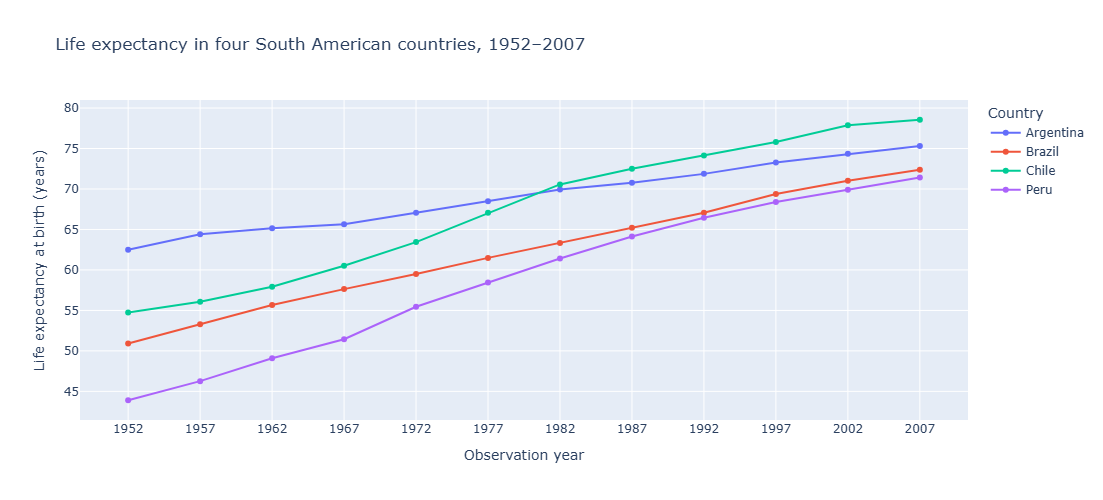

In [13]:
life_line = px.line(
    life,
    x="year",
    y="lifeExp",
    color="country",
    markers=True,
    labels={
        "year": "Observation year",
        "lifeExp": "Life expectancy at birth (years)",
        "country": "Country"
    },
    title="Life expectancy in four South American countries, 1952–2007"
)
life_line.update_xaxes(tick0=1952, dtick=5)
life_line.update_layout(height=500)
life_line.show()

**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer: Life expectancy rose in all four countries from 1952 to 2007. Argentina started with the highest life expectancy in 1952, but Chile passed it by the 1982 observation. Chile ended with the highest life expectancy of the four in 2007 at 78.553 years. 

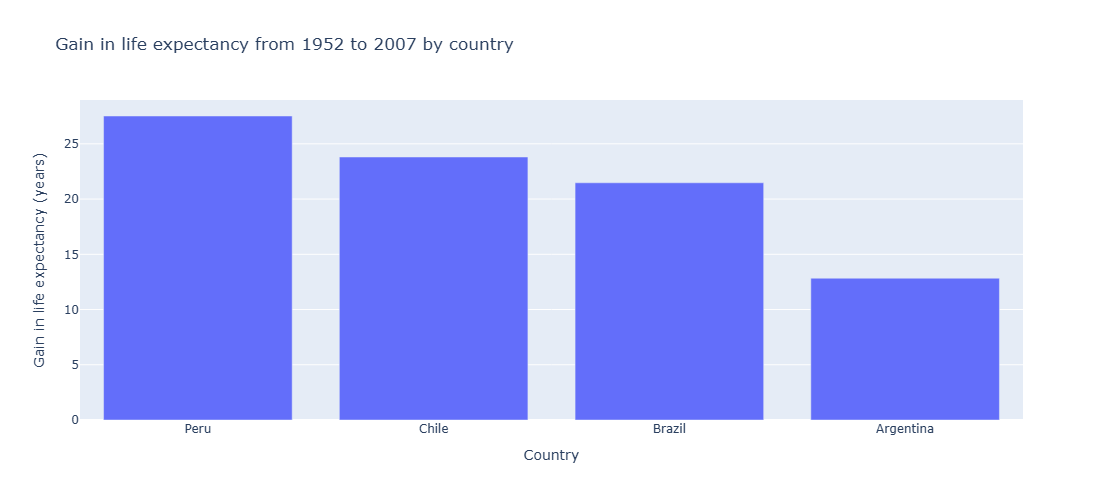

In [14]:
life_bar = px.bar(
    gains,
    x="country",
    y="gain",
    hover_data={"start": ":.3f", "end": ":.3f"},
    labels={
        "country": "Country",
        "gain": "Gain in life expectancy (years)",
        "start": "1952 life expectancy (years)",
        "end": "2007 life expectancy (years)"
    },
    title="Gain in life expectancy from 1952 to 2007 by country"
)
life_bar.update_yaxes(rangemode="tozero")
life_bar.update_layout(height=500)
life_bar.show()

**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer: Figure 2 makes it easier to compare how many years each country gained. Peru gained the most, at 27.519 years from 1952 to 2007. Figure 1 shows how life expectancy changed throughout the period and that Chile finished highest. Figure 2 shows that Peru improved the most over the full period. 

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [15]:
peru_source = gapminder_df.loc[
    (gapminder_df["country"] == "Peru") & gapminder_df["year"].isin([1952, 2007]),
    ["year", "lifeExp"]
].set_index("year")["lifeExp"]

peru_line = next(trace for trace in life_line.data if trace.name == "Peru")
peru_2007 = dict(zip(peru_line.x, peru_line.y))[2007]
peru_bar = dict(zip(life_bar.data[0].x, life_bar.data[0].y))["Peru"]
peru_gain = round(peru_source.loc[2007] - peru_source.loc[1952], 3)

assert peru_2007 == peru_source.loc[2007]
assert peru_bar == peru_gain
assert peru_bar == max(life_bar.data[0].y)
assert {trace.name for trace in life_line.data} == set(countries)
assert set(life_bar.data[0].x) == set(countries)

for trace in life_line.data:
    assert list(trace.x) == list(range(1952, 2008, 5))

print("Peru's 2007 life expectancy:", peru_2007, "years")
print("Peru's gain from 1952 to 2007:", peru_gain, "years") 

Peru's 2007 life expectancy: 71.421 years
Peru's gain from 1952 to 2007: 27.519 years


**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer: I checked Peru’s 2007 point in Figure 1. It showed 71.421 years, which matched the original record. I also checked Peru’s bar in Figure 2. It showed a gain of 27.519 years, which matched 71.421 minus 43.902 from the source data. Both figures used the same four countries, and the line chart showed the years in order. Peru started at the lowest life expectancy of the four and had the largest gain. 

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer: My question was how life expectancy changed in Argentina, Brazil, Chile, and Peru from 1952 to 2007 and which country gained the most years. Figure 1 showed that all four countries improved. Peru went from 43.902 years in 1952 to 71.421 years in 2007, while Chile finished highest at 78.553 years in 2007. Figure 2 showed that Peru gained 27.519 years, more than Chile’s gain of 23.808 years or either of the other countries. This supported both parts of my prediction. 

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer: The data only has an observation every five years, so changes between those years are hard to see. Also, each value is a national estimate, which can hide differences within a country. The line chart makes it easy to see trends and when Chile passed Argentina, but comparing the total gains takes some subtraction. The bar chart makes it easy to see that Peru gained the most, but it leaves out what happened between 1952 and 2007. 

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I used ChatGPT to help choose the datasets, troubleshoot Python errors, and put the charts together. I used my own predictions and rewrote the explanations in my own words. One suggestion I checked was filtering the Gapminder data to Argentina, Brazil, Chile, and Peru. I kept that filter after my notebook showed 48 records and no unmatched country names, which gave me 12 observations per country. 

## Submission checklist

- Include two distinct datasets, each with both usable spatial and temporal information, plus any lookup or boundary files.
- Document both sources, feature definitions, units, collection context, coverage, and download filters.
- Complete the feature table and every written response for both investigations.
- Ask one research question per dataset and complete all six workflow steps for each question.
- Include four finished figures: two different chart types for each question, with each pair addressing both space and time.
- Explain filtering, missing values, aggregations, row counts, and any changes in the unit of observation.
- Check plotted values, temporal order, and geographic interpretation against the data.
- Restate each question in its conclusion and support the answer with evidence from both figures.
- Identify two limitations per investigation and compare what the two displays reveal or obscure.
- Complete the AI-use reflection. Restart the kernel, run cells in order, and ensure interactive figures display correctly before submitting.